In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from linearmodels.panel import PanelOLS
import numpy as np

In [6]:
INDEX_COLS = ['alpha', 'beta', 'gamma']
QUARTER_PANEL_PATH = '../data/checkpoints/panel_q.csv'
BIANNUAL_PANEL_PATH = '../data/checkpoints/panel_h.csv'
FULL_PANEL_PATH = '../data/checkpoints/panel_q_full.csv'

TELEWORK_PATH = '../data/telework_cps_level.csv'

GRAPHS_PATH = '../temp/graphics/graphs/'
TABLES_PATH = '../temp/graphics/tables/'
EVENT_STUDY_FOLDER = 'event_studies/'


REFERENCE_QUINTILE = 1

quintiles = [1,2,3,4,5]
quintiles.remove(REFERENCE_QUINTILE)

DV_COL = 'Y_SHARE'
DV_NAME = 'Entry-Level Workers Share'

In [7]:
panel_q = pd.read_csv(QUARTER_PANEL_PATH)
panel_h = pd.read_csv(BIANNUAL_PANEL_PATH)
panel_full = pd.read_csv(FULL_PANEL_PATH)

tele = pd.read_csv(TELEWORK_PATH)

In [8]:
print(panel_h.columns)


Index(['OCC', 'HALF_YEAR', 'N', 'np', 'tech', '_wN', '_wnp', '_wtech', 'alpha',
       'beta', 'gamma', 'Y_SHARE', 'TECH_SHARE', 'W_Y_SHARE', 'W_TECH_SHARE',
       'alpha_quintile', 'alpha_quintile_1', 'alpha_quintile_2',
       'alpha_quintile_3', 'alpha_quintile_4', 'alpha_quintile_5',
       'beta_quintile', 'beta_quintile_1', 'beta_quintile_2',
       'beta_quintile_3', 'beta_quintile_4', 'beta_quintile_5',
       'gamma_quintile', 'gamma_quintile_1', 'gamma_quintile_2',
       'gamma_quintile_3', 'gamma_quintile_4', 'gamma_quintile_5'],
      dtype='str')


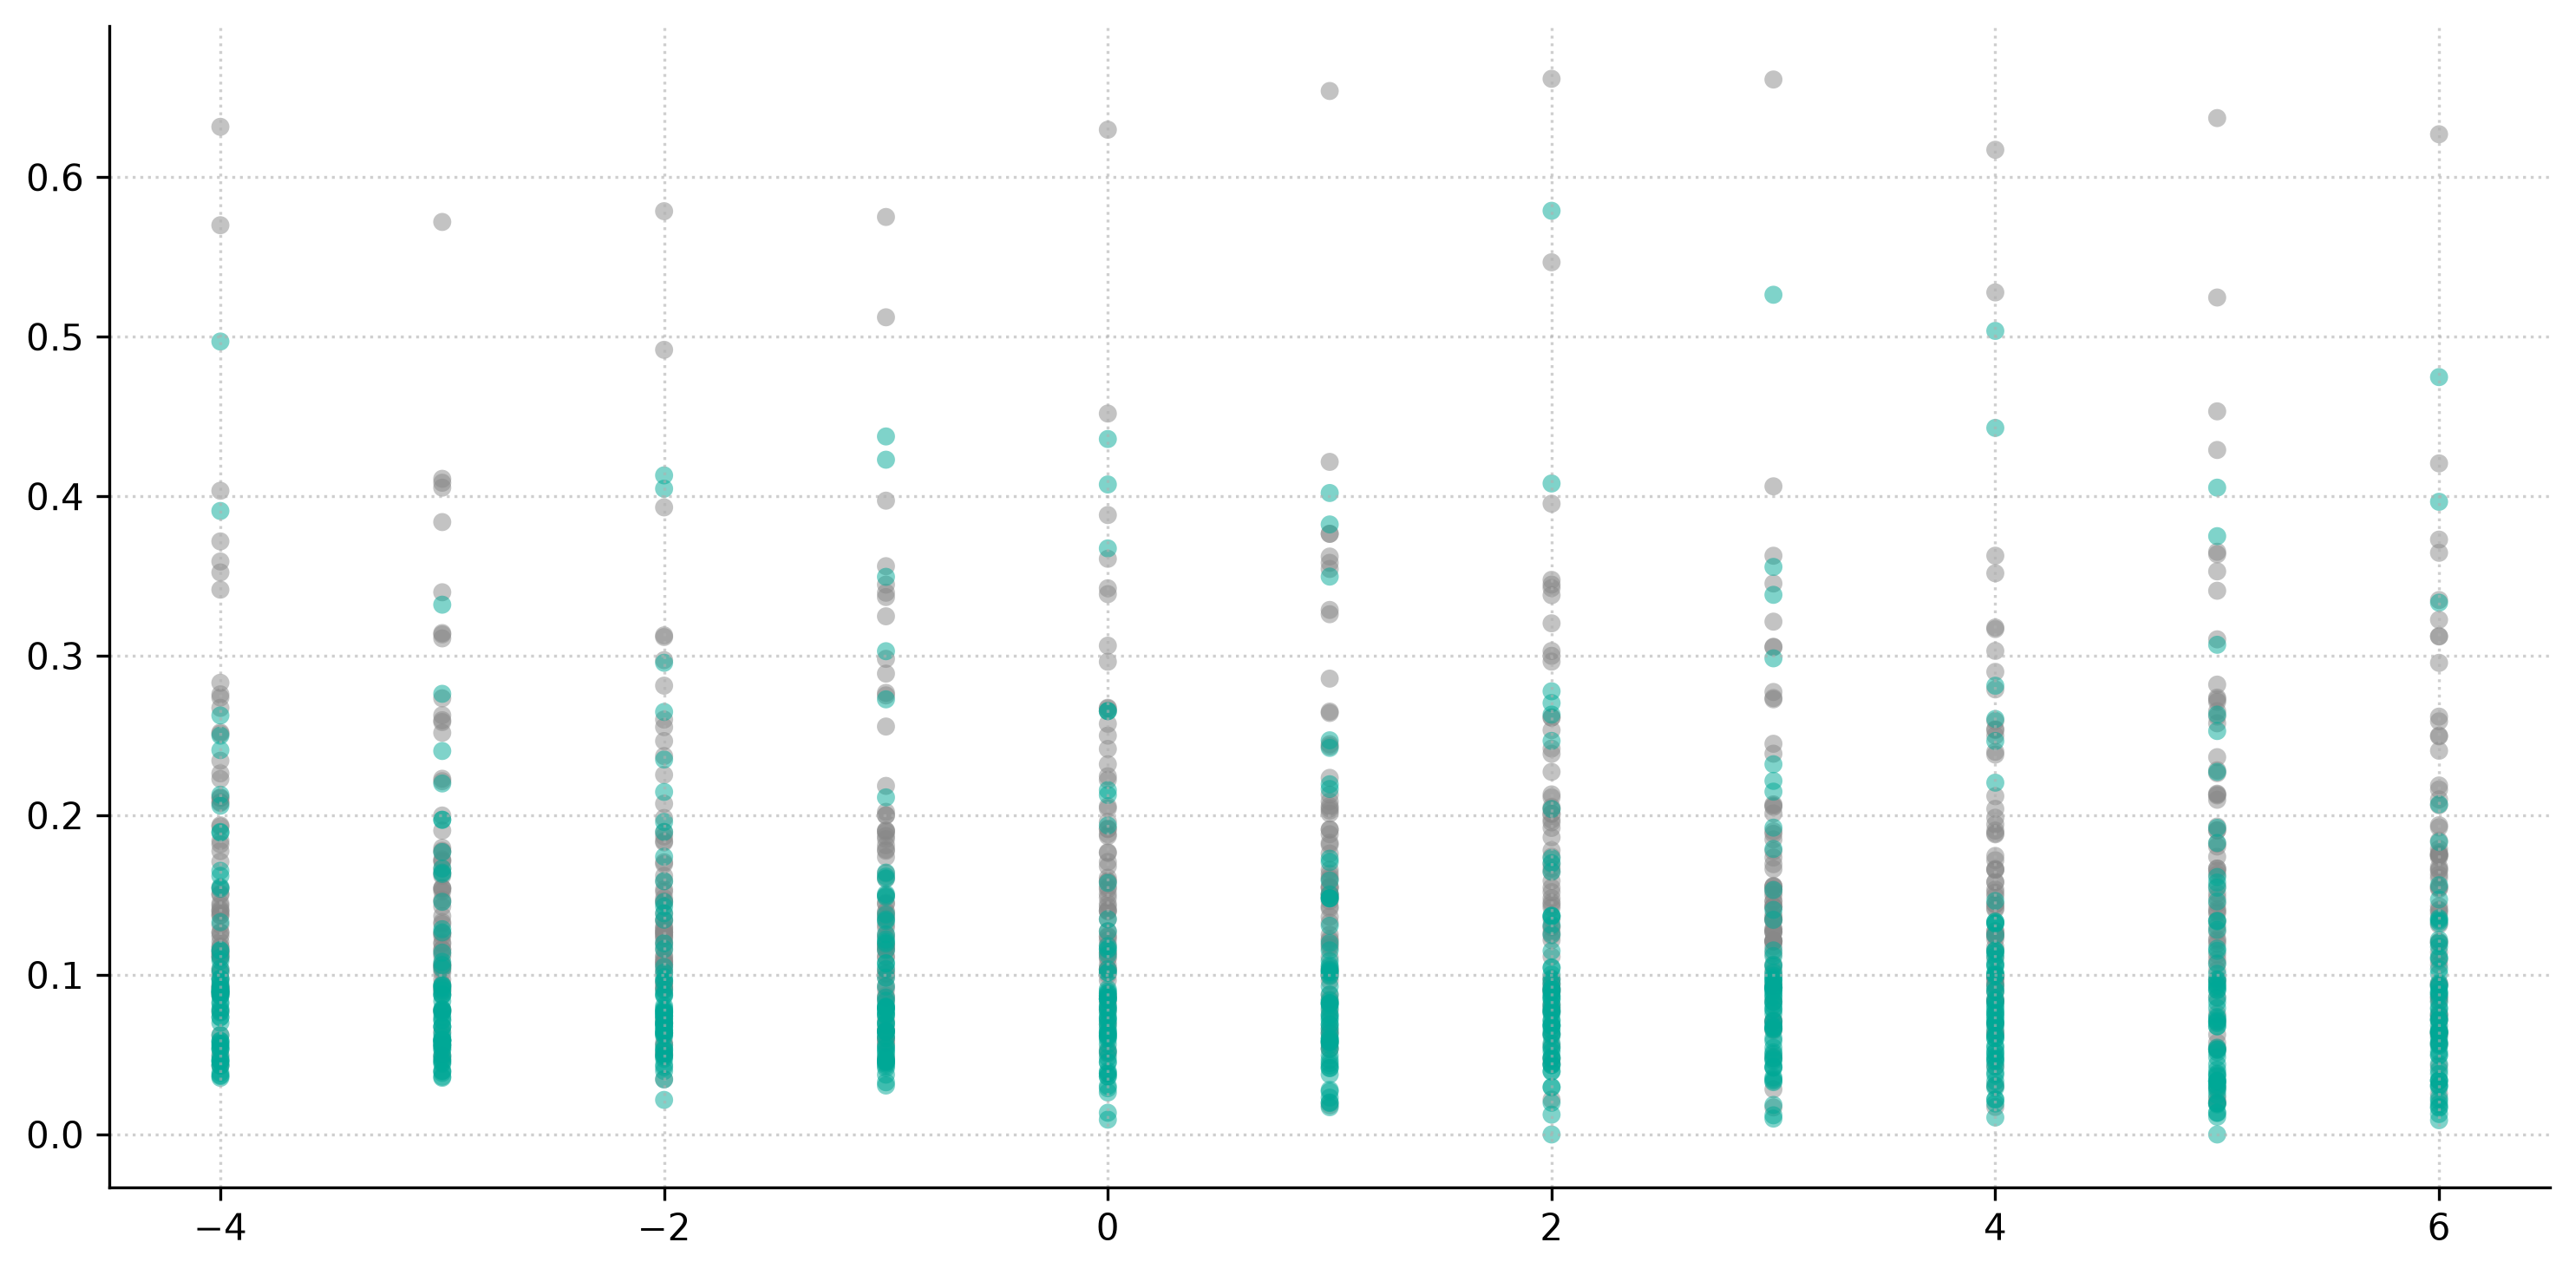

In [9]:
filtered = panel_h[panel_h['beta_quintile'].isin([1, 5])]

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

treat = filtered[filtered['beta_quintile'] == 5]
ref = filtered[filtered['beta_quintile'] == 1]
ax.scatter(ref['HALF_YEAR'], ref['Y_SHARE'], color='#888888', s=25, alpha=0.5, edgecolors='none')
ax.scatter(treat['HALF_YEAR'], treat['Y_SHARE'], color='#00A896',s=25, alpha=0.5, edgecolors='none')

ax.grid(True, linestyle=':', alpha=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()


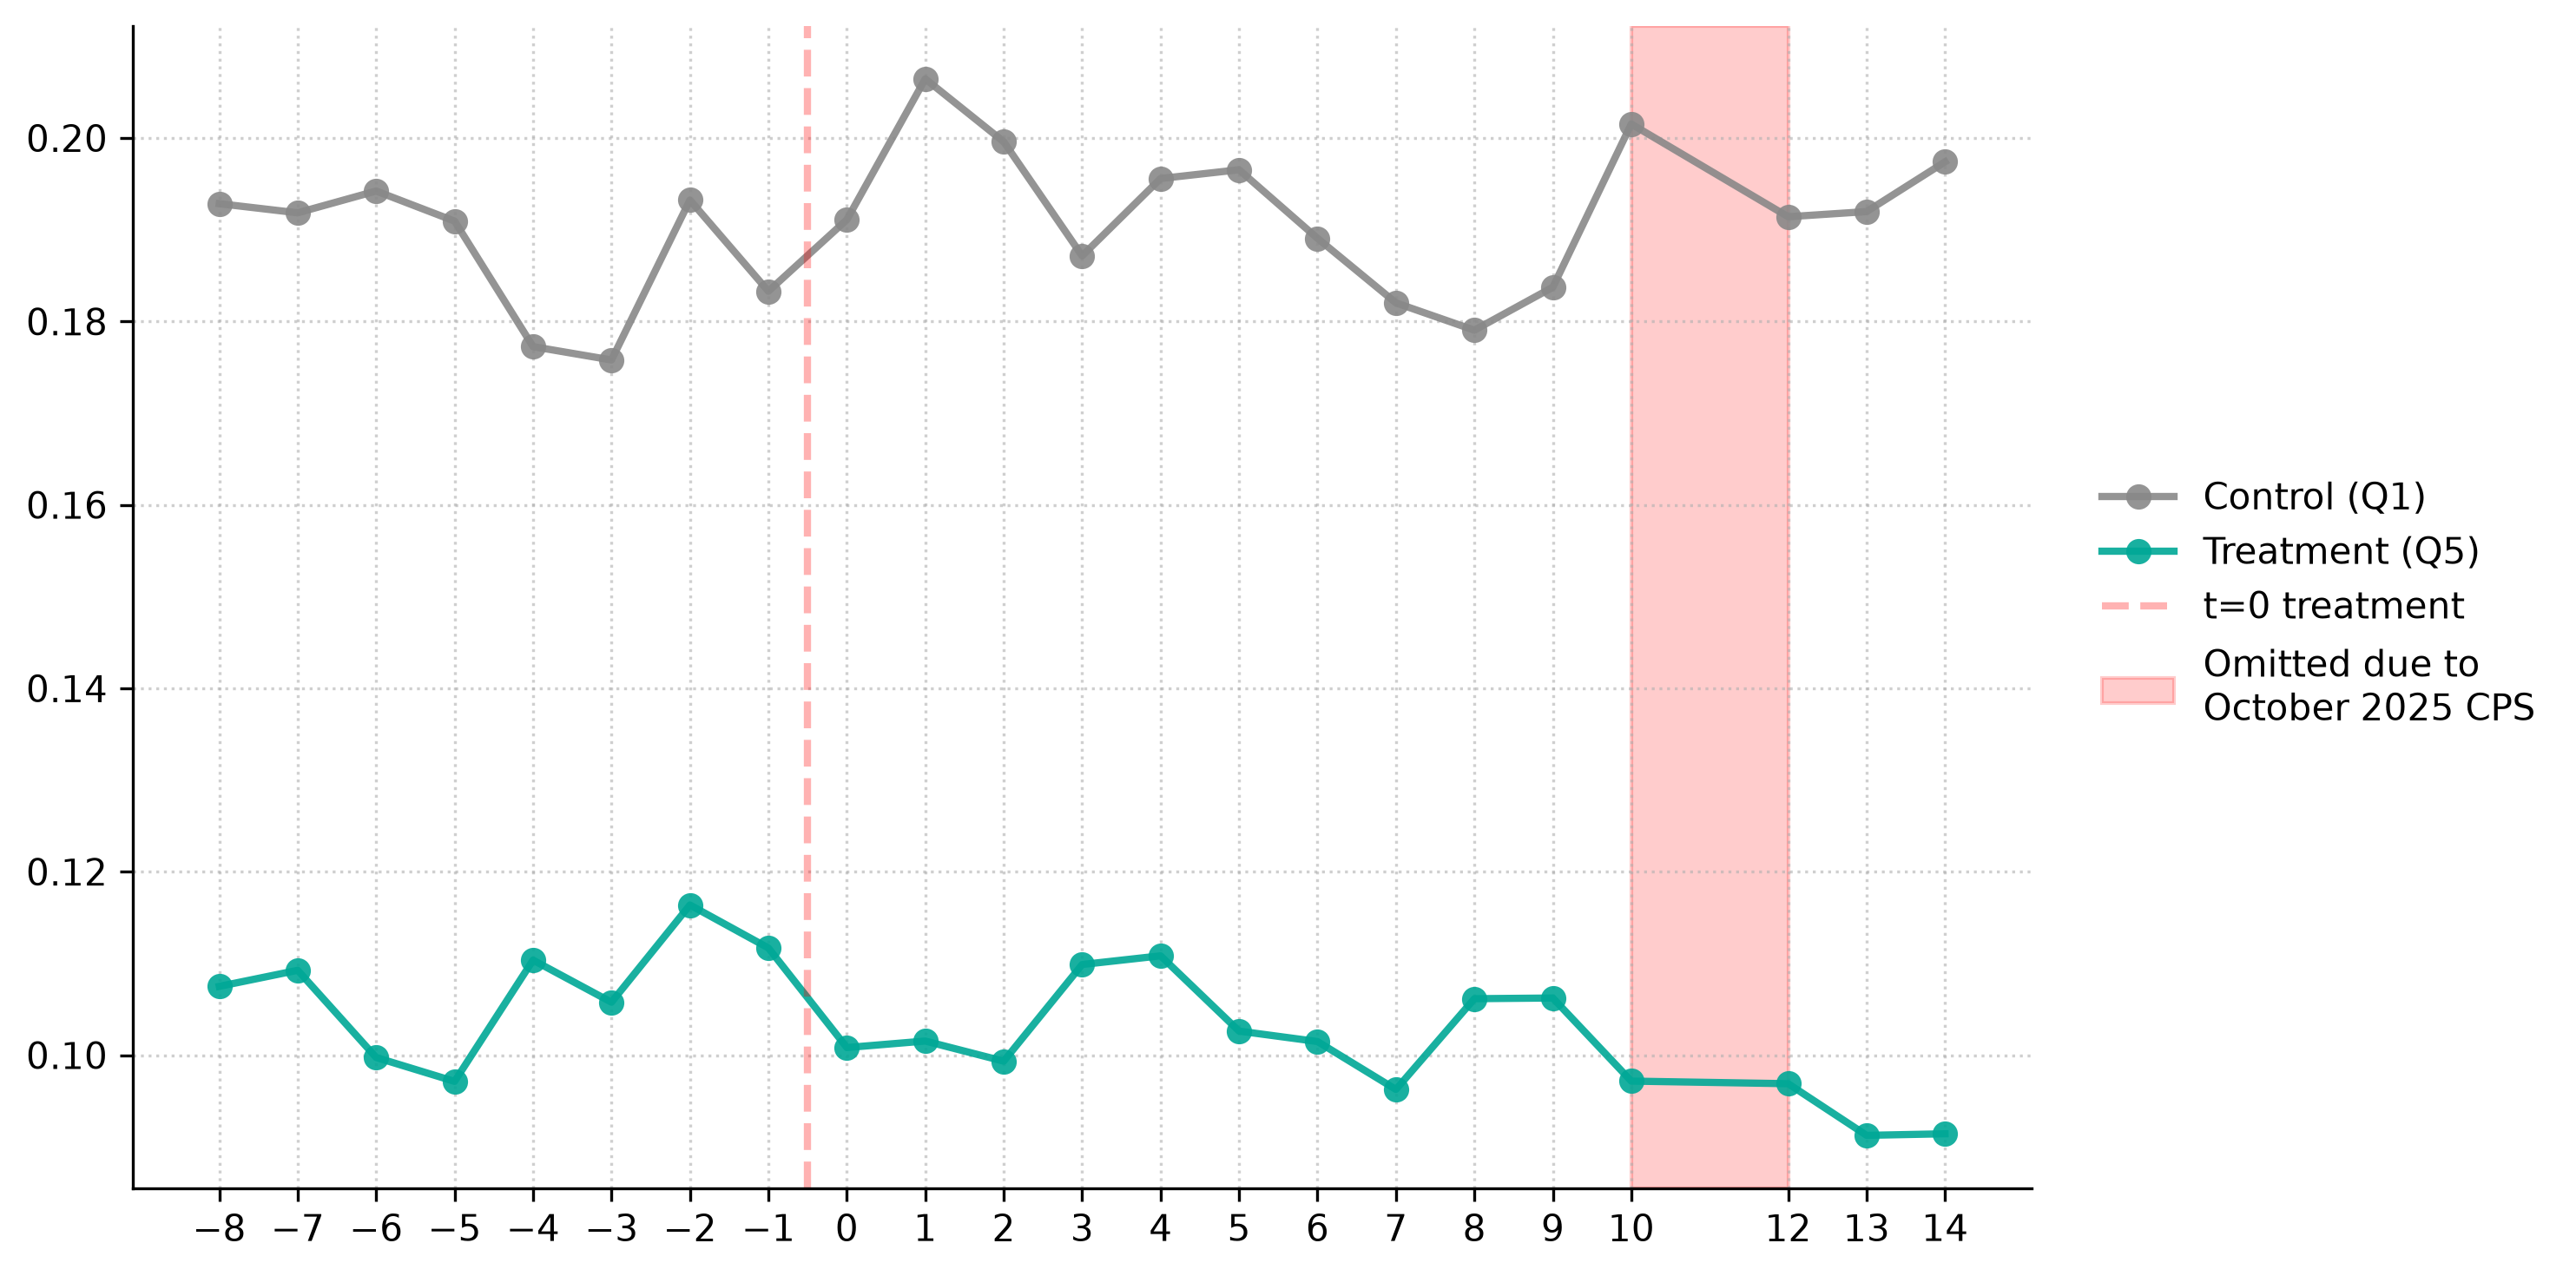

In [10]:
filtered = panel_q[panel_q['beta_quintile'].isin([1, 5])]

grouped = filtered.groupby(['QUARTER', 'beta_quintile'])["Y_SHARE"].mean().reset_index()

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

colors = {1: '#888888', 5: '#00A896'}
labels = {1: 'Control (Q1)', 5: 'Treatment (Q5)'}

for quintile, data in grouped.groupby('beta_quintile'):
    ax.plot(
        data['QUARTER'], 
        data['Y_SHARE'], 
        color=colors[quintile], 
        label=labels[quintile],
        linewidth=2,
        marker='o',             # Adds point markers along line
        markersize=7,
        markeredgecolor='none', # Removes dark border around markers
        alpha=0.9
    )
    
ax.set_xticks(filtered['QUARTER'].unique())
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.axvline(x=-0.5, color='r', linestyle='--', linewidth=2, alpha=0.3, label="t=0 treatment")
ax.axvspan(10, 12, color='r', alpha = 0.2, label= "Omitted due to\nOctober 2025 CPS")

ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5))

ax.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()


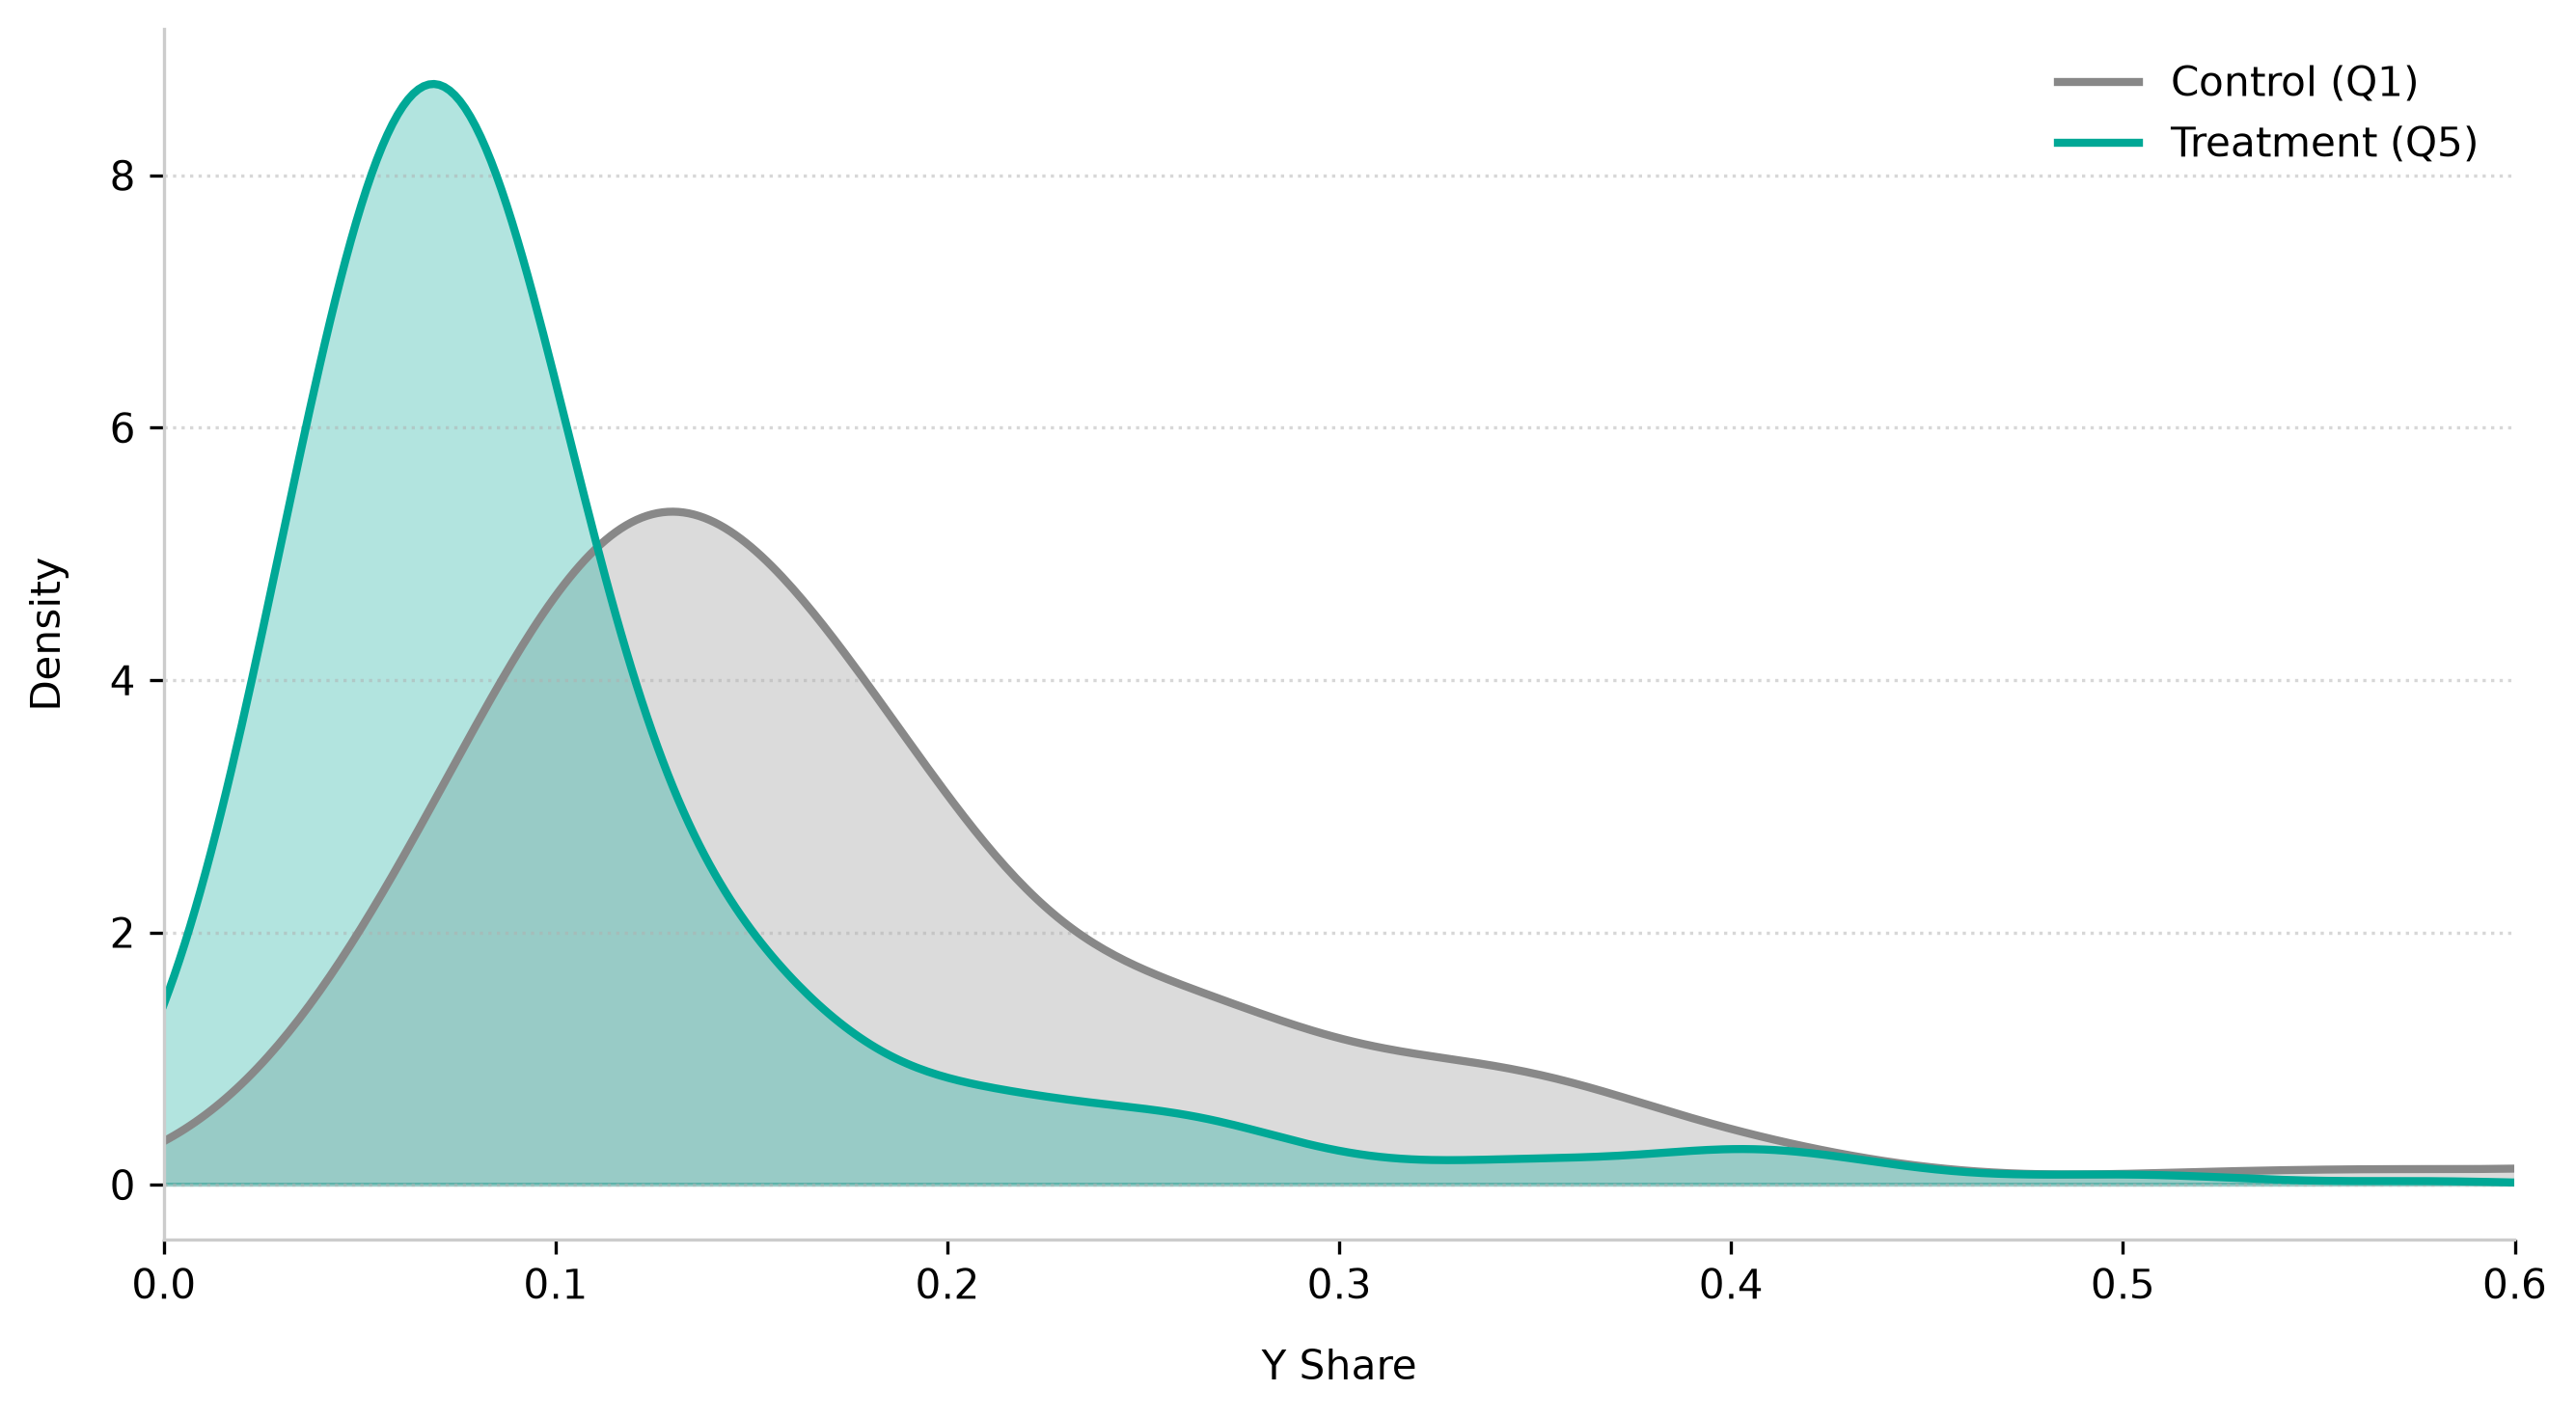

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import gaussian_kde

filtered = panel_h[panel_h['beta_quintile'].isin([1, 5])]

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)

colors = {1: '#888888', 5: '#00A896'}
labels = {1: 'Control (Q1)', 5: 'Treatment (Q5)'}

# Evaluate density across data range
x_eval = np.linspace(filtered['Y_SHARE'].min(), filtered['Y_SHARE'].max(), 500)

for quintile, data in filtered.groupby('beta_quintile'):
    # Calculate KDE line
    density = gaussian_kde(data['Y_SHARE'].dropna())
    y_eval = density(x_eval)
    
    # Plot line
    ax.plot(x_eval, y_eval, color=colors[quintile], label=labels[quintile], linewidth=2)
    # Fill area under curve for overlay effect
    ax.fill_between(x_eval, y_eval, color=colors[quintile], alpha=0.3)

# Clean borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.legend(frameon=False)
ax.set_xlabel("Y Share", labelpad=10)
ax.set_ylabel("Density", labelpad=10)
ax.set_xlim(0,.6)

plt.tight_layout()
plt.show()

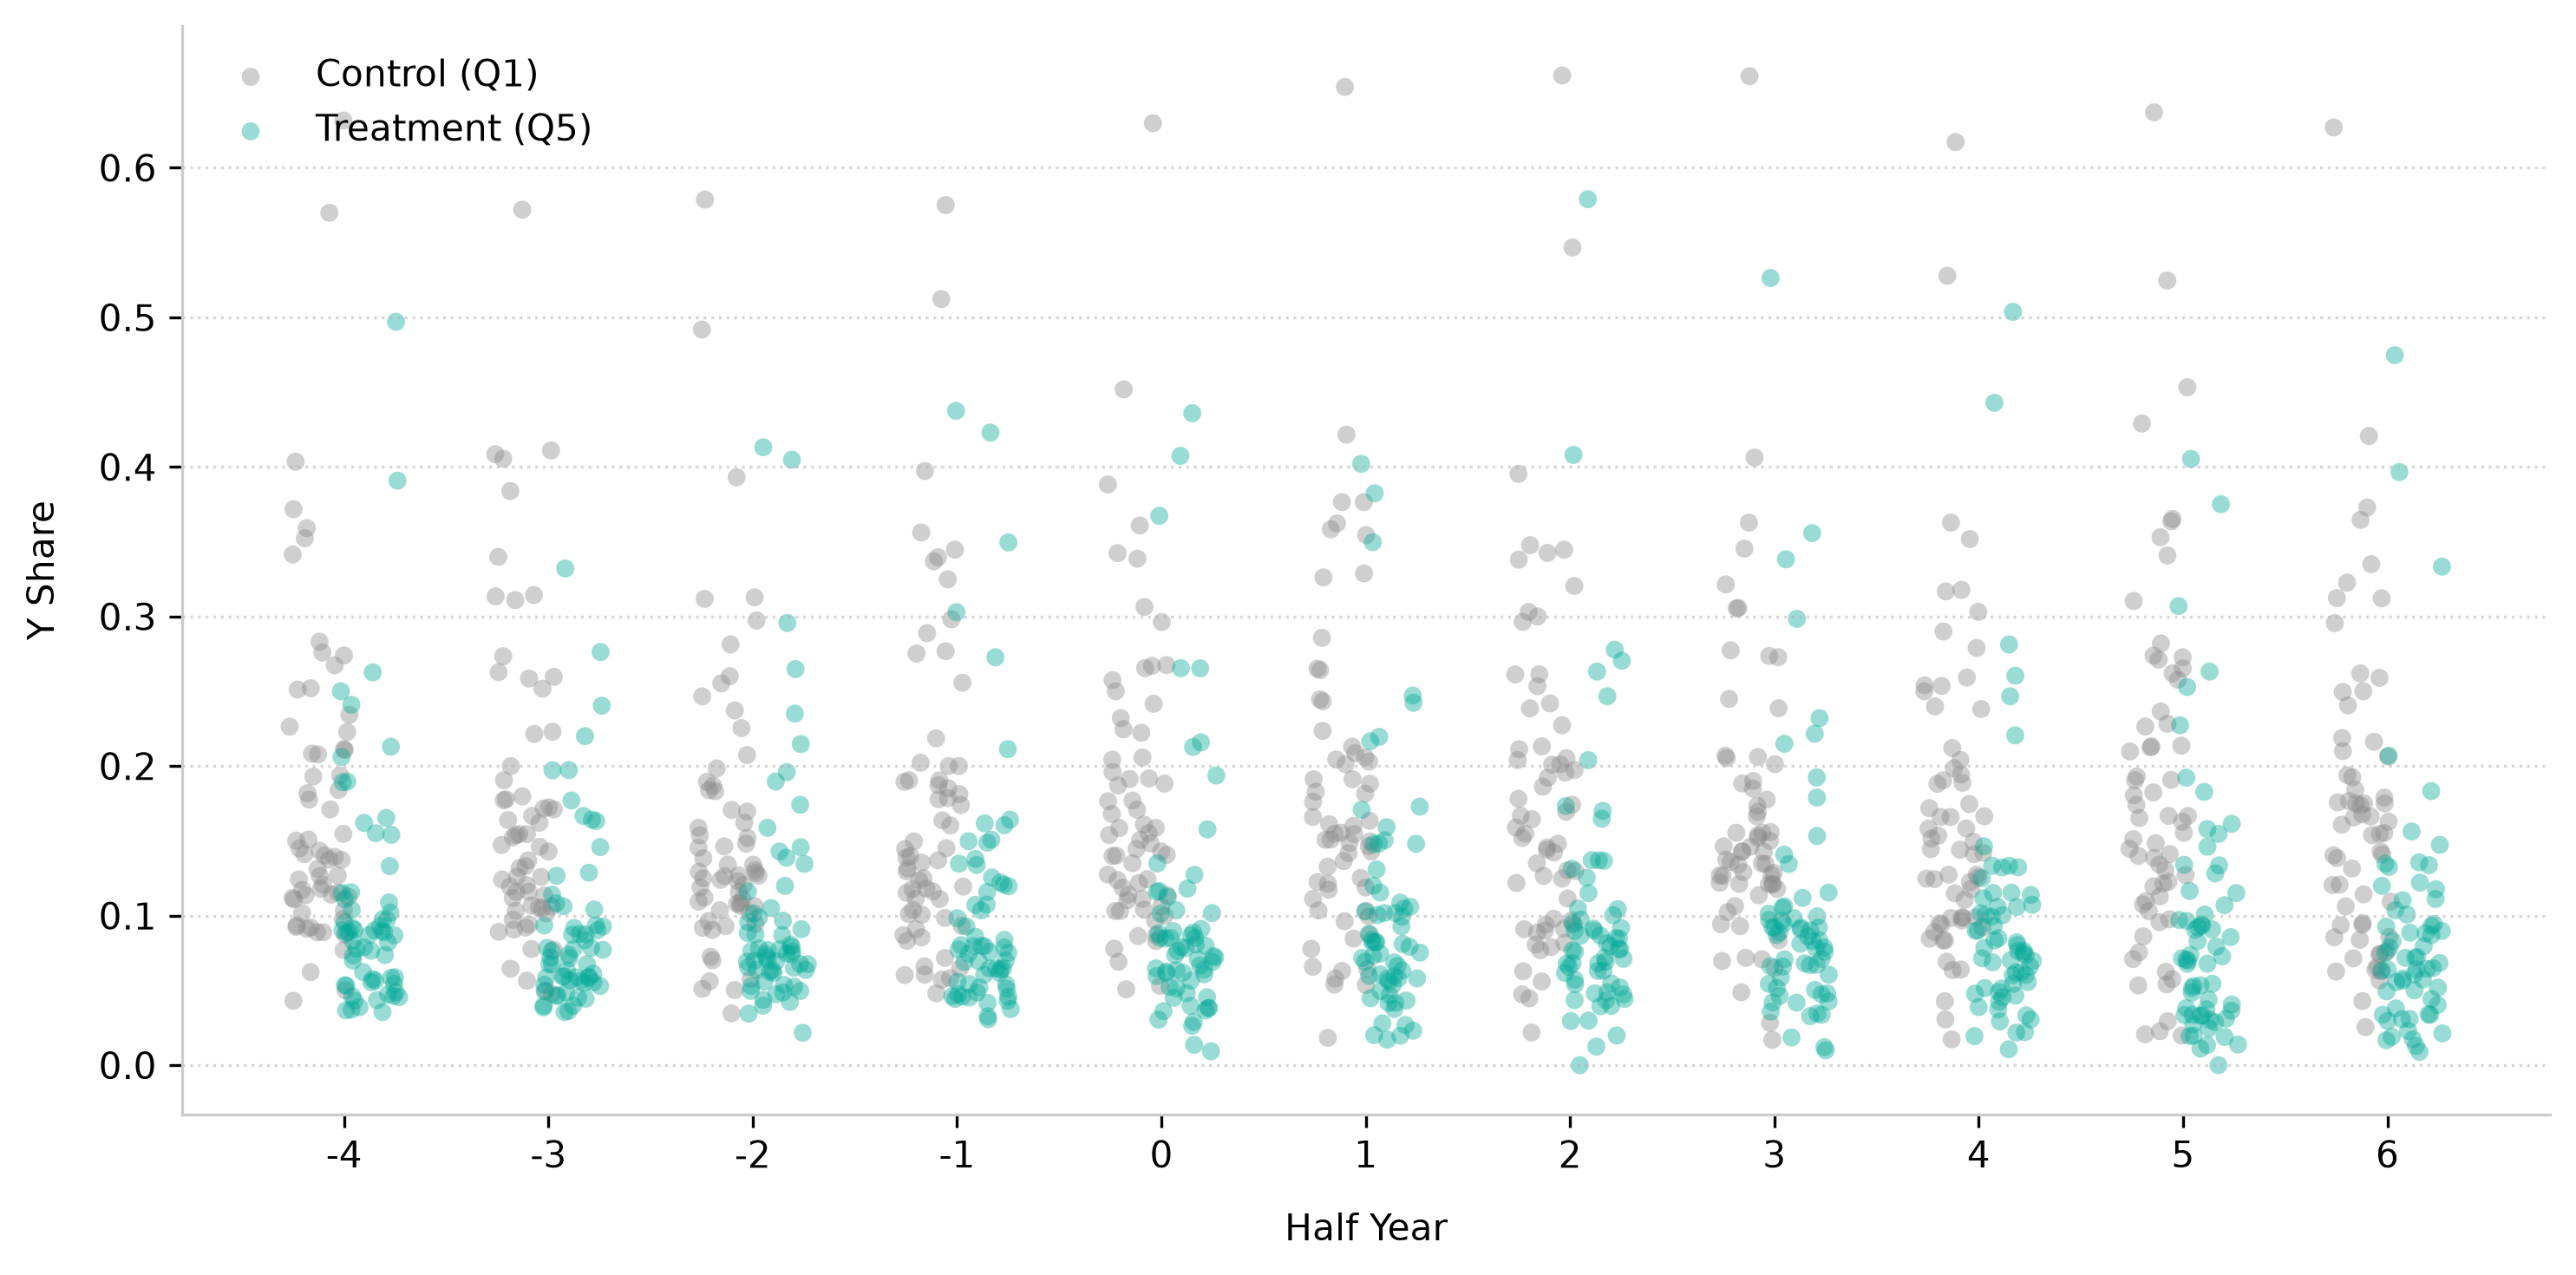

In [13]:
import matplotlib.pyplot as plt
import numpy as np

filtered = panel_h[panel_h['beta_quintile'].isin([1, 5])].copy()

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

colors = {1: '#888888', 5: '#00A896'}
labels = {1: 'Control (Q1)', 5: 'Treatment (Q5)'}

# Unique time periods
time_points = sorted(filtered['HALF_YEAR'].unique())
time_map = {val: i for i, val in enumerate(time_points)}

np.random.seed(42)  # For consistent jitter

for quintile, group in filtered.groupby('beta_quintile'):
    # Map time to numeric indices
    x_coords = group['HALF_YEAR'].map(time_map).values
    
    # Add random horizontal jitter (between -0.15 and +0.15)
    jitter = np.random.uniform(-0.15, 0.15, size=len(x_coords))
    
    # Offset Q1 to left, Q5 to right so groups don't blend
    offset = -0.12 if quintile == 1 else 0.12
    
    ax.scatter(
        x_coords + jitter + offset,
        group['Y_SHARE'],
        color=colors[quintile],
        label=labels[quintile],
        alpha=0.4,          # Transparency reveals dense point overlaps
        s=25,
        edgecolors='none'
    )

# Formatting time axis
ax.set_xticks(range(len(time_points)))
ax.set_xticklabels(time_points)

# Border & grid cleanup
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.legend(frameon=False)
ax.set_xlabel("Half Year", labelpad=10)
ax.set_ylabel("Y Share", labelpad=10)

plt.tight_layout()
plt.show()

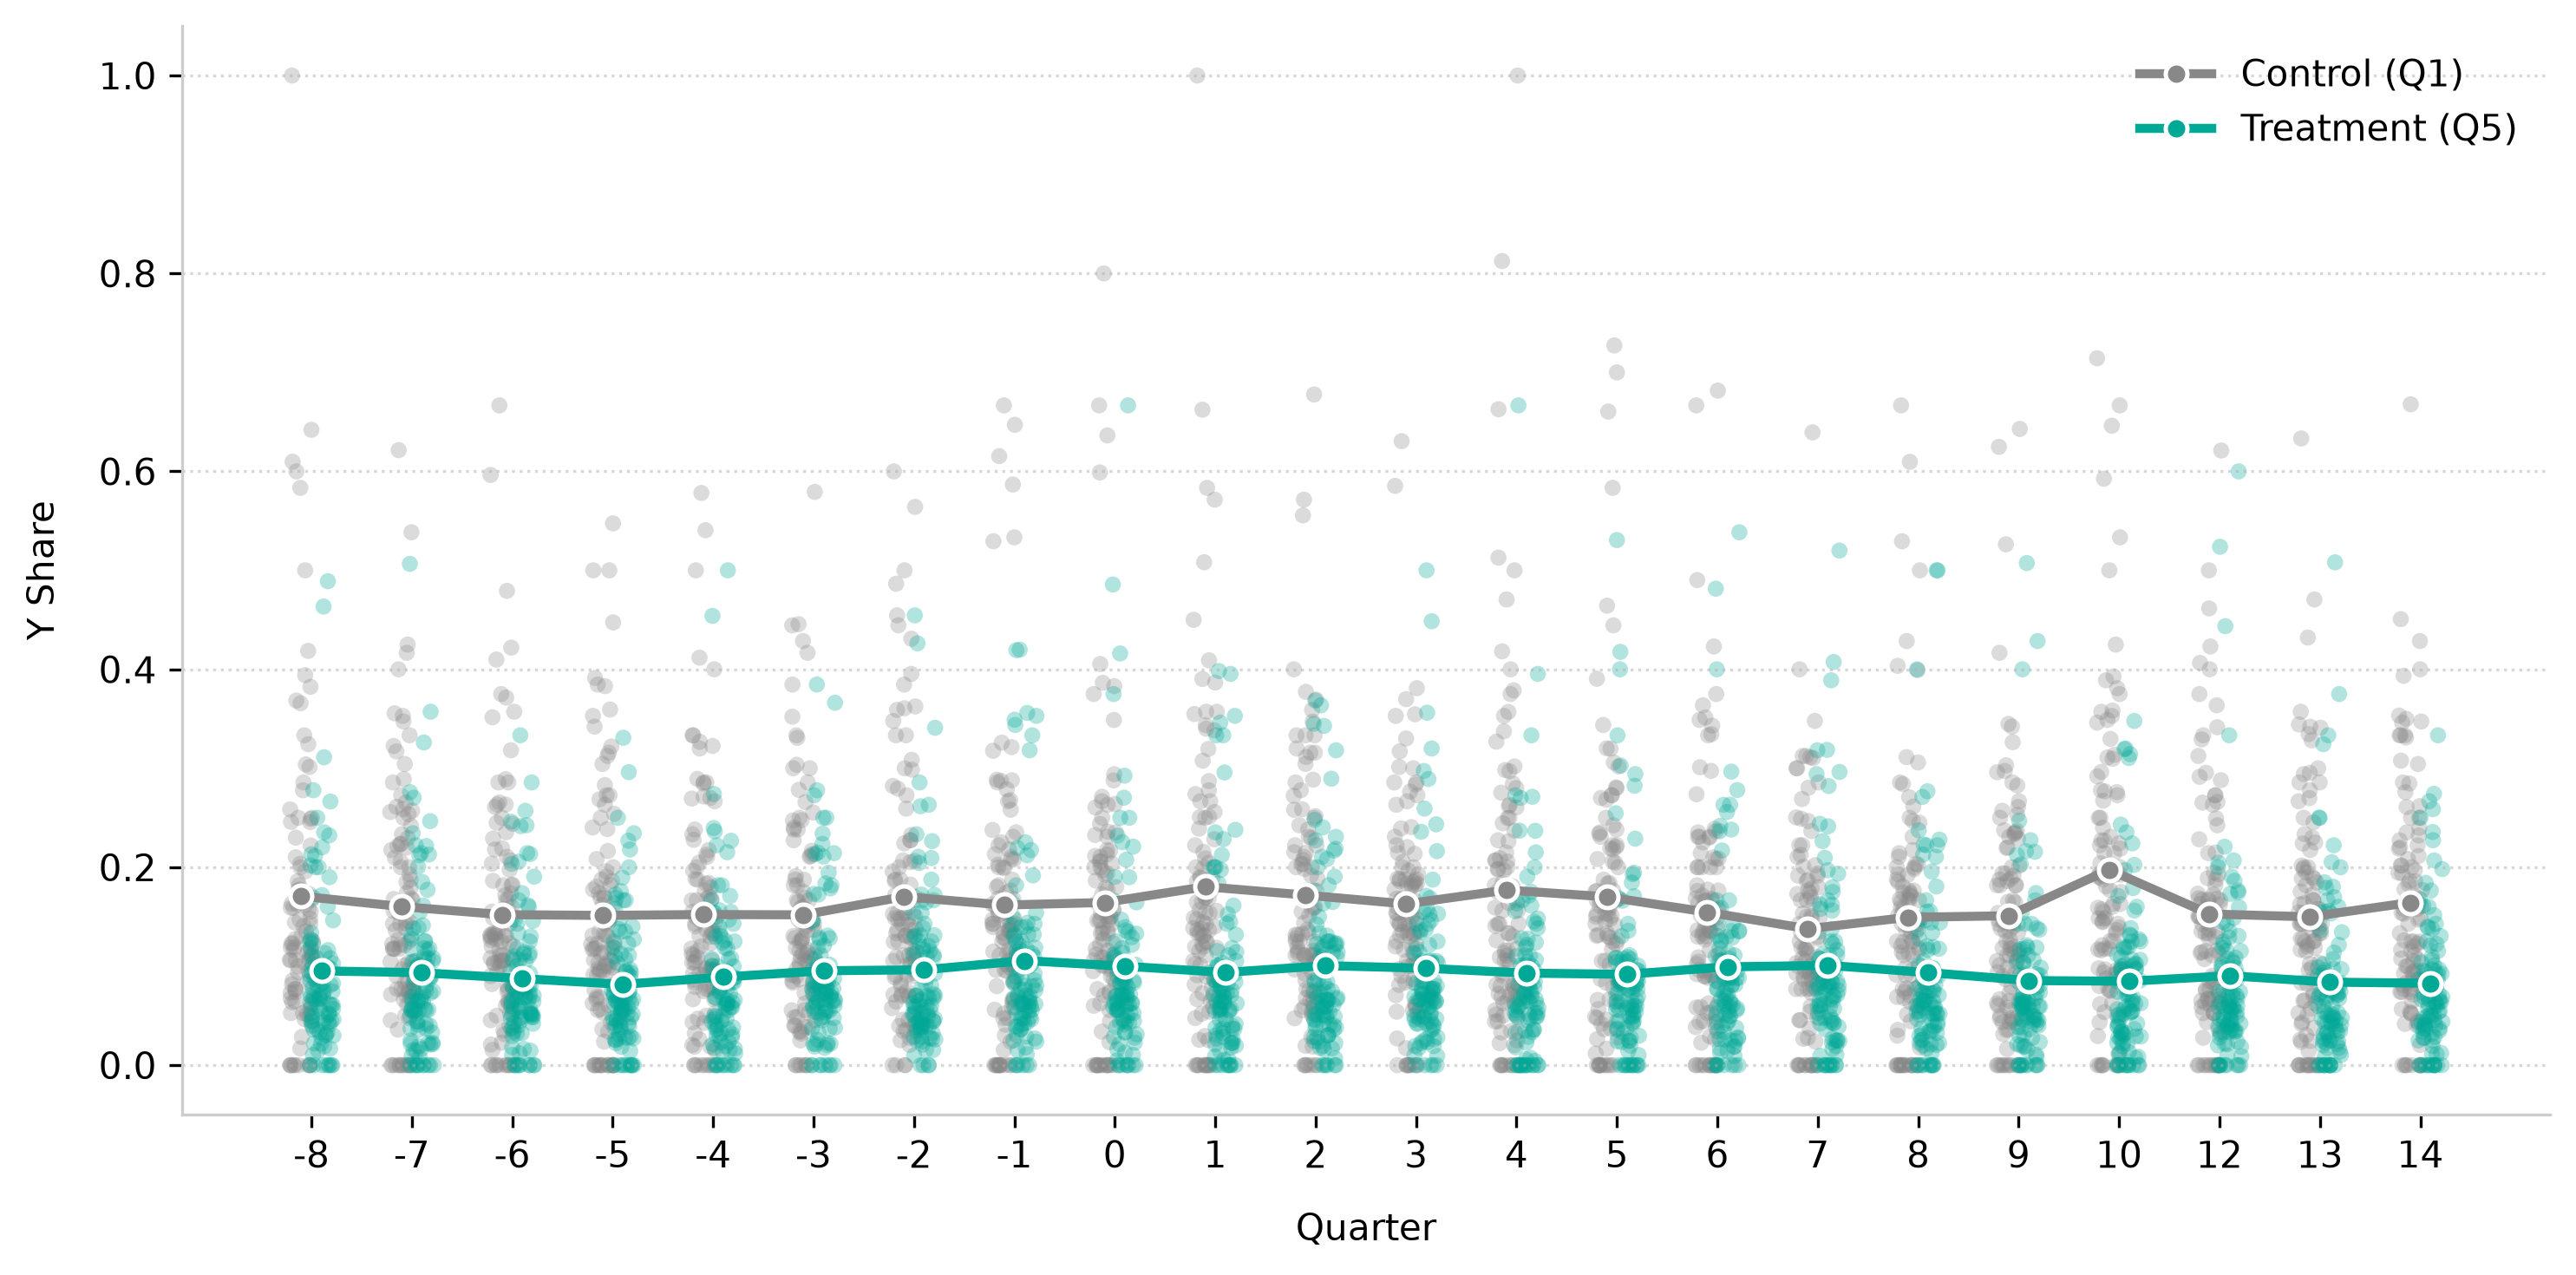

In [16]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Filter for beta_quintile (1, 5) and copy dataframe
filtered = panel_full[panel_full['beta_quintile'].isin([1, 5])].copy()

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

colors = {1: '#888888', 5: '#00A896'}
labels = {1: 'Control (Q1)', 5: 'Treatment (Q5)'}

# Unique time periods (Quarters)
time_points = sorted(filtered['QUARTER'].unique())
time_map = {val: i for i, val in enumerate(time_points)}

np.random.seed(42)  # For consistent jitter

# 2. Calculate quarter means per quintile
means = filtered.groupby(['QUARTER', 'beta_quintile'])['Y_SHARE'].mean().reset_index()

for quintile, group in filtered.groupby('beta_quintile'):
    # Map quarters to numeric indices
    x_coords = group['QUARTER'].map(time_map).values
    
    # Add random horizontal jitter
    jitter = np.random.uniform(-0.12, 0.12, size=len(x_coords))
    offset = -0.10 if quintile == 1 else 0.10
    
    # Plot raw scatter points with jitter
    ax.scatter(
        x_coords + jitter + offset,
        group['Y_SHARE'],
        color=colors[quintile],
        alpha=0.3,             # Light transparency so dense areas pop out
        s=20,
        edgecolors='none'
    )

    # Filter group means and map X coordinates
    group_means = means[means['beta_quintile'] == quintile].sort_values('QUARTER')
    mean_x_coords = group_means['QUARTER'].map(time_map).values + offset

    # 3. Plot connected mean line over scatter points
    ax.plot(
        mean_x_coords,
        group_means['Y_SHARE'],
        color=colors[quintile],
        label=labels[quintile],
        linewidth=2.5,
        marker='o',
        markersize=6,
        markeredgecolor='white',
        markeredgewidth=1.2,
        zorder=5               # Keeps mean line above scatter dots
    )

# Formatting time axis
ax.set_xticks(range(len(time_points)))
ax.set_xticklabels(time_points)

# Border & grid cleanup
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.legend(frameon=False)
ax.set_xlabel("Quarter", labelpad=10)
ax.set_ylabel("Y Share", labelpad=10)

plt.tight_layout()
plt.show()

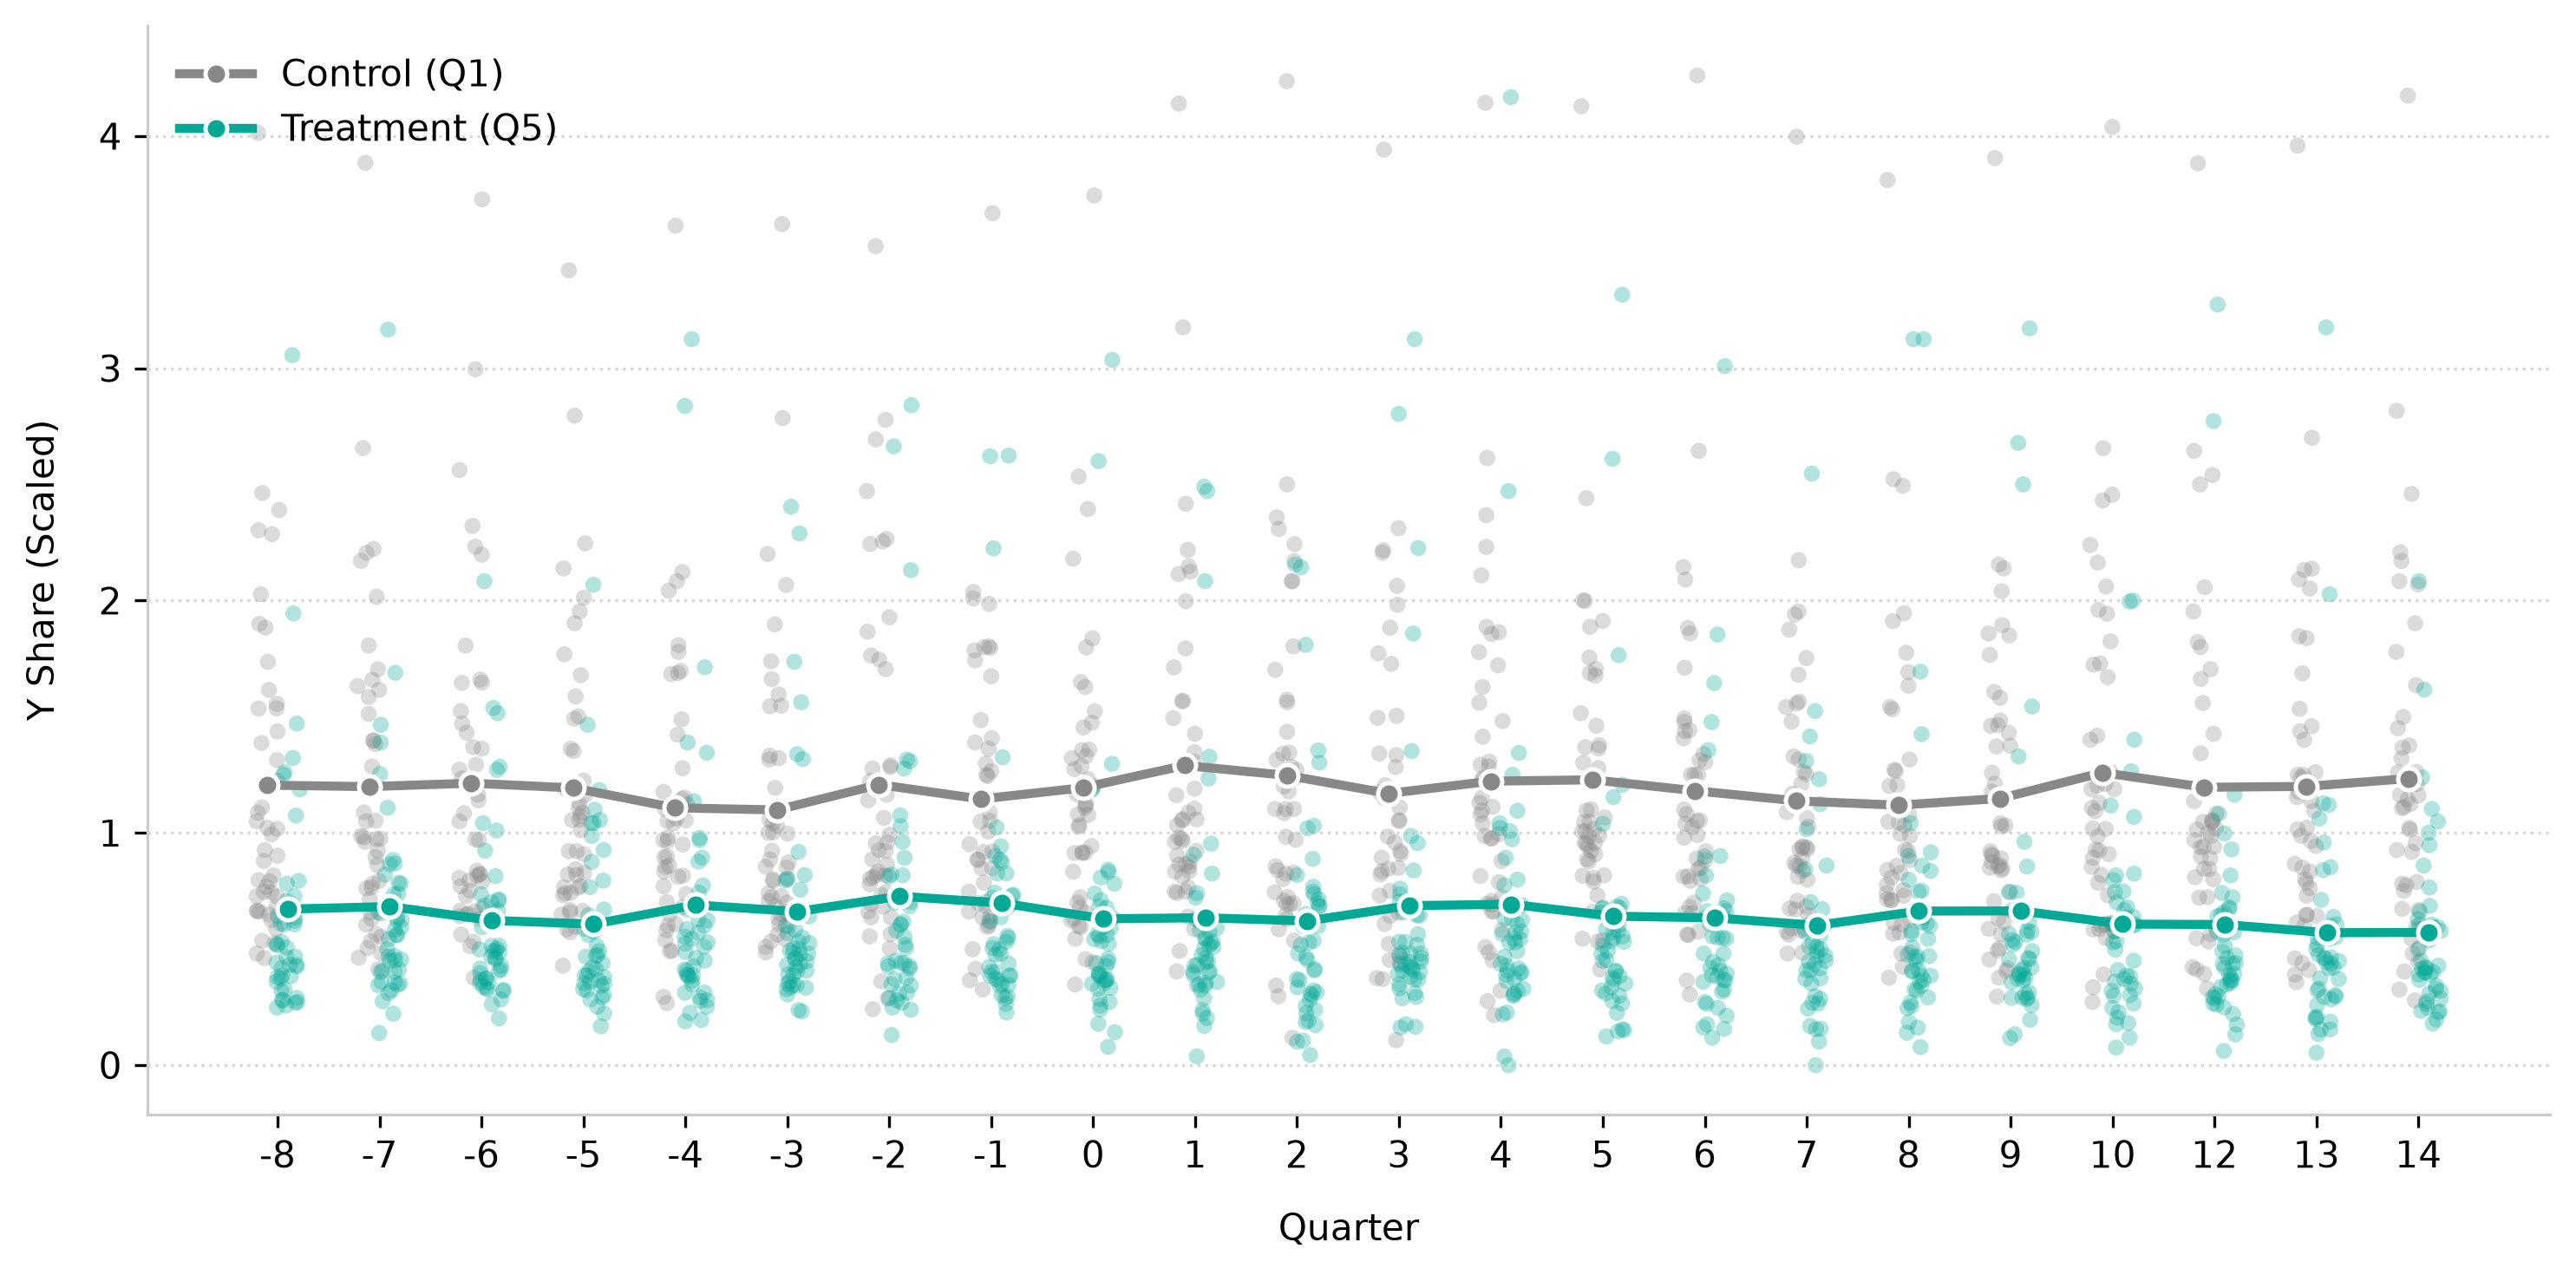

In [15]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Filter for beta_quintile (1, 5), copy dataframe, and divide Y_SHARE by 0.16
filtered = panel_q[panel_q['beta_quintile'].isin([1, 5])].copy()
filtered['Y_SHARE'] = filtered['Y_SHARE'] / 0.16

fig, ax = plt.subplots(figsize=(10, 5), dpi=300)

colors = {1: '#888888', 5: '#00A896'}
labels = {1: 'Control (Q1)', 5: 'Treatment (Q5)'}

# Unique time periods (Quarters)
time_points = sorted(filtered['QUARTER'].unique())
time_map = {val: i for i, val in enumerate(time_points)}

np.random.seed(42)  # For consistent jitter

# 2. Calculate quarter means per quintile (using the scaled Y_SHARE)
means = filtered.groupby(['QUARTER', 'beta_quintile'])['Y_SHARE'].mean().reset_index()

for quintile, group in filtered.groupby('beta_quintile'):
    # Map quarters to numeric indices
    x_coords = group['QUARTER'].map(time_map).values
    
    # Add random horizontal jitter
    jitter = np.random.uniform(-0.12, 0.12, size=len(x_coords))
    offset = -0.10 if quintile == 1 else 0.10
    
    # Plot raw scatter points with jitter
    ax.scatter(
        x_coords + jitter + offset,
        group['Y_SHARE'],
        color=colors[quintile],
        alpha=0.3,             # Light transparency so dense areas pop out
        s=20,
        edgecolors='none'
    )

    # Filter group means and map X coordinates
    group_means = means[means['beta_quintile'] == quintile].sort_values('QUARTER')
    mean_x_coords = group_means['QUARTER'].map(time_map).values + offset

    # 3. Plot connected mean line over scatter points
    ax.plot(
        mean_x_coords,
        group_means['Y_SHARE'],
        color=colors[quintile],
        label=labels[quintile],
        linewidth=2.5,
        marker='o',
        markersize=6,
        markeredgecolor='white',
        markeredgewidth=1.2,
        zorder=5               # Keeps mean line above scatter dots
    )

# Formatting time axis
ax.set_xticks(range(len(time_points)))
ax.set_xticklabels(time_points)

# Border & grid cleanup
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_color('#cccccc')
ax.spines['bottom'].set_color('#cccccc')

ax.grid(axis='y', linestyle=':', alpha=0.5)
ax.legend(frameon=False)
ax.set_xlabel("Quarter", labelpad=10)
ax.set_ylabel("Y Share (Scaled)", labelpad=10)

plt.tight_layout()
plt.show()